# Does the Loyalty Program Drive Repeat Purchases?

**Request (Loyalty Program Owner):** The program is up for renewal. Do members actually buy again more than non-members, or does it just look that way?

**Data:** `fct_orders` from the Vantra dbt pipeline (BigQuery), 2019–2022. Revenue rule applied: $0 and missing-price orders excluded, refunds kept, each order counted once.

**Approach:** Build one row per customer → compare repeat rates → check for bias → test whether the gap is real.


## 1. Setup
Connect Colab to the BigQuery project so the notebook queries the same tested dbt marts used across the project.

In [136]:
from google.colab import auth

auth.authenticate_user()
print("Authenticated")


Authenticated


## 2. Build the customer table
One row per customer (87,540), built in SQL before moving to pandas:
- **Loyalty member:** "ever a member" (`LOGICAL_OR`). 534 customers (0.6%) had mixed flags across orders, likely joining mid-way, and are counted as members.
- **First purchase date:** the customer's earliest order
- **Order count:** distinct orders, so the 5 duplicated orders count once
- **Repeat customer:** 2+ orders



In [137]:
from google.cloud import bigquery
client = bigquery.Client(project="vantra-514719")

In [138]:
import pandas as pd
import numpy as np

In [139]:
sql = """
select user_id, LOGICAL_OR(is_loyalty_member) as is_loyalty_member, min(purchase_date) as first_purchase_date, count(distinct(order_id)) as order_count
from dbt_bpan.fct_orders
where purchase_date is not null
  and is_zero_price is false
  and is_missing_price is false
group by 1;
"""

customers_df = client.query(sql).to_dataframe()
customers_df.head()

,user_id,is_loyalty_member,first_purchase_date,order_count
0,e8ee5408,False,2019-01-01,1
1,32698d45,False,2019-01-01,1
2,12fd4613,False,2019-01-01,2
3,4beb2ca1,True,2019-01-01,2
4,dff5a022,False,2019-01-01,1


In [140]:
customers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87540 entries, 0 to 87539
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   user_id              87540 non-null  object 
 1   is_loyalty_member    87540 non-null  boolean
 2   first_purchase_date  87540 non-null  dbdate 
 3   order_count          87540 non-null  Int64  
dtypes: Int64(1), boolean(1), dbdate(1), object(1)
memory usage: 2.3+ MB


- How many customers are members vs non-members?
- For each group, what’s the repeat rate (% with 2+ orders)?
- Compare both groups by first-purchase year. Are members mostly recent customers?

In [141]:
customers_df['is_loyalty_member'].value_counts()

,count
is_loyalty_member,
False,48282
True,39258


534 customers had both member and non-member orders in fct_orders, likely joining mid-way, and are counted as members.

## 3. First look: repeat rate by membership
At face value, members come back *less* often: **17.3%** vs **21.6%** for non-members. Before trusting this, we check whether the two groups are comparable.

In [142]:
customers_df['is_repeat_customer'] =  customers_df['order_count'].apply(lambda x: True if x>1 else False)

customers_df.head()

,user_id,is_loyalty_member,first_purchase_date,order_count,is_repeat_customer
0,e8ee5408,False,2019-01-01,1,False
1,32698d45,False,2019-01-01,1,False
2,12fd4613,False,2019-01-01,2,True
3,4beb2ca1,True,2019-01-01,2,True
4,dff5a022,False,2019-01-01,1,False


In [143]:
repeat_rate = customers_df.groupby('is_loyalty_member')['is_repeat_customer'].mean()
repeat_rate


,is_repeat_customer
is_loyalty_member,
False,0.216478
True,0.172755


In [144]:
customers_df['first_purchase_year'] = pd.to_datetime(customers_df['first_purchase_date']).dt.year
customers_df.head()

,user_id,is_loyalty_member,first_purchase_date,order_count,is_repeat_customer,first_purchase_year
0,e8ee5408,False,2019-01-01,1,False,2019
1,32698d45,False,2019-01-01,1,False,2019
2,12fd4613,False,2019-01-01,2,True,2019
3,4beb2ca1,True,2019-01-01,2,True,2019
4,dff5a022,False,2019-01-01,1,False,2019


## 4. Checking for bias: members are newer customers
Members' share of each year's new customers grew from **12% (2019)** to **~57% (2021–22)**. Newer customers have had less time to come back, so comparing all members to all non-members is unfair. To fix this, we compare members and non-members **within the same first-purchase year**.

In [145]:
cohort_sizes = customers_df.groupby(['first_purchase_year','is_loyalty_member'])['is_repeat_customer'].size()
cohort_sizes

first_purchase_year  is_loyalty_member
2019                 False                12066
                     True                  1622
2020                 False                16198
                     True                 11008
2021                 False                12223
                     True                 16749
2022                 False                 7795
                     True                  9879
Name: is_repeat_customer, dtype: int64

<Axes: title={'center': 'Most Loyalty Members Are Newer Customers (2020–2022)'}, xlabel='first_purchase_year'>

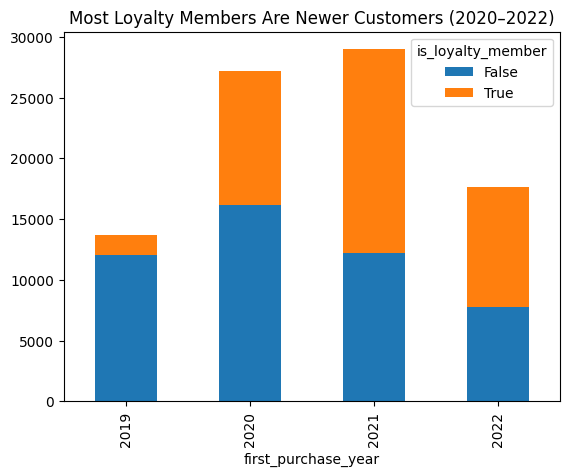

In [146]:
cohort_sizes.unstack(level=-1, fill_value=None, sort=True,).plot(kind='bar', stacked =True, title="Most Loyalty Members Are Newer Customers (2020–2022)")


In [147]:
repeat_rate = customers_df.groupby(['first_purchase_year','is_loyalty_member'])['is_repeat_customer'].mean()
repeat_rate

first_purchase_year  is_loyalty_member
2019                 False                0.244157
                     True                 0.270654
2020                 False                0.232189
                     True                 0.198583
2021                 False                0.197497
                     True                 0.174518
2022                 False                0.170750
                     True                 0.124911
Name: is_repeat_customer, dtype: float64

## 5. Repeat rate within each year
Comparing customers who started in the same year, members still repeat less in 3 of 4 years:

| Year | Non-members | Members | Gap |
|---|---|---|---|
| 2019 | 24.4% | 27.1% | +2.7 pts |
| 2020 | 23.2% | 19.9% | −3.4 pts |
| 2021 | 19.7% | 17.5% | −2.3 pts |
| 2022 | 17.1% | 12.5% | −4.6 pts |

<Axes: title={'center': 'Loyalty Members Come Back Less Often Than Non-Members (Except 2019)'}, xlabel='first_purchase_year'>

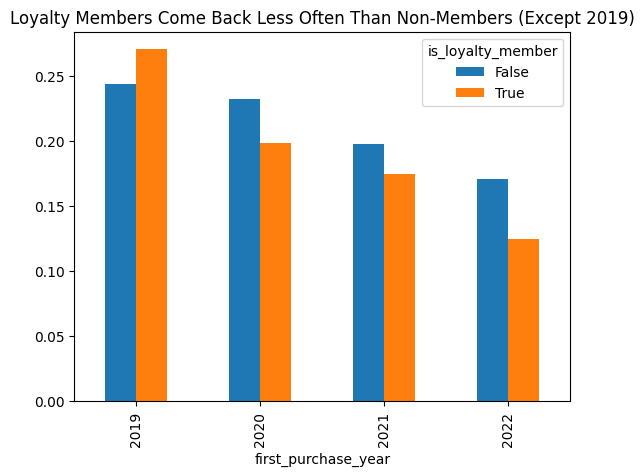

In [148]:
repeat_rate.unstack(level=-1, fill_value=None, sort=True).plot(kind='bar', title="Loyalty Members Come Back Less Often Than Non-Members (Except 2019)")


Example: one year (2022) before running all four

In [149]:
filtered_df = customers_df[customers_df['first_purchase_year'] == 2022]

In [150]:
import scipy.stats as stats
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(filtered_df['is_loyalty_member'], filtered_df['is_repeat_customer'])
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print(p_value)

1.046144679778823e-17


## 6. Is the gap real? Chi-square test by year
For each year, a chi-square test asks: *if membership had no effect, how likely is a gap this large by chance?* A p-value below 0.05 means chance is an unlikely explanation. Because four tests are run, a stricter threshold of 0.0125 (0.05 ÷ 4) is also applied.

| Year | p-value | Result |
|---|---|---|
| 2019 | 0.022 | Members higher, not conclusive at the stricter threshold |
| 2020 | < 0.0001 | Members significantly lower |
| 2021 | < 0.0001 | Members significantly lower |
| 2022 | < 0.0001 | Members significantly lower |

In [151]:
for value in sorted(customers_df['first_purchase_year'].unique()):
  filtered_df = customers_df[customers_df['first_purchase_year'] == value]
  contingency_table = pd.crosstab(filtered_df['is_loyalty_member'], filtered_df['is_repeat_customer'])
  chi2, p_value, dof, expected = chi2_contingency(contingency_table)
  print(f"For {value}: {p_value}")


For 2019: 0.021930683995745347
For 2020: 5.1008238499426545e-11
For 2021: 6.784856740030925e-07
For 2022: 1.046144679778823e-17


## 7. Verdict for the Loyalty Program Owner
The loyalty program is **not associated with more repeat purchases**. Among customers who started in the same year, members were **2–5 percentage points less likely** to buy again in 2020, 2021 and 2022, and these gaps are statistically significant. 2019 members did slightly better, but that result is not conclusive.

**Recommendation:** don't renew the program as-is. Redesign the incentive to reward coming back (for example, points or discounts on a second purchase) rather than generous refunds, which may attract try-and-return shoppers.

**Caveats:**
- This shows an association, not proof that the program *causes* lower repeat buying.
- The data doesn't record *when* customers joined the program.
- Refunds stop being recorded after Aug 2021, so the refund hypothesis can't be fully tested here.